<div align="center">

# ЗВІТ
### до практичної роботи № 1
### з дисципліни «ЕМПІ»
### «Попередня обробка та контрольована класифікація даних»

<br><br>
</div>

<div align="right">

**Виконав:**<br>
студент групи ТЦР-44<br>
Овчарук А. О.

<br>

**Перевірив:**<br>
Садовенко В. С.

</div>

<br><br>
<div align="center">2026</div>

**Мета роботи:** використовуючи спеціалізовані бібліотеки та мову програмування Python дослідити попередню обробку та класифікацію даних.

**Посилання на GitHub:** https://github.com/Phent1s/EMPI

## Завдання 2.1. Попередня обробка даних
*Завдання:* задати вибірку даних `input_data` та виконати бінаризацію (поріг 2.1), виключення середнього, масштабування MinMax, L1- та L2-нормалізацію, а також кодування міток. Зробити висновок про відмінність L1- та L2-нормалізації.

Підключено numpy та модуль preprocessing з sklearn, задано масив вхідних даних і по черзі застосовано всі методи попередньої обробки: `Binarizer` з порогом 2.1, `scale` для виключення середнього, `MinMaxScaler` з діапазоном (0, 1) та `normalize` з параметрами `norm='l1'` і `norm='l2'`.

In [1]:
import numpy as np
from sklearn import preprocessing

input_data = np.array([[5.1, -2.9, 3.3],
                       [-1.2, 7.8, -6.1],
                       [3.9, 0.4, 2.1],
                       [7.3, -9.9, -4.5]])

# Бінаризація даних
data_binarized = preprocessing.Binarizer(threshold=2.1).transform(input_data)
print("\n Binarized data:\n", data_binarized)

# Виведення середнього значення та стандартного відхилення
print("\nBEFORE: ")
print("Mean =", input_data.mean(axis=0))
print("Std deviation =", input_data.std(axis=0))

# Виключення середнього
data_scaled = preprocessing.scale(input_data)
print("\nAFTER: ")
print("Mean =", data_scaled.mean(axis=0))
print("Std deviation =", data_scaled.std(axis=0))

# Масштабування MinMax
data_scaler_minmax = preprocessing.MinMaxScaler(feature_range=(0, 1))
data_scaled_minmax = data_scaler_minmax.fit_transform(input_data)
print("\nMin max scaled data:\n", data_scaled_minmax)

# Нормалізація даних
data_normalized_l1 = preprocessing.normalize(input_data, norm='l1')
data_normalized_l2 = preprocessing.normalize(input_data, norm='l2')
print("\nl1 normalized data:\n", data_normalized_l1)
print("\nl2 normalized data:\n", data_normalized_l2)


 Binarized data:
 [[1. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]

BEFORE: 
Mean = [ 3.775 -1.15  -1.3  ]
Std deviation = [3.12039661 6.36651396 4.0620192 ]

AFTER: 
Mean = [1.11022302e-16 0.00000000e+00 2.77555756e-17]
Std deviation = [1. 1. 1.]

Min max scaled data:
 [[0.74117647 0.39548023 1.        ]
 [0.         1.         0.        ]
 [0.6        0.5819209  0.87234043]
 [1.         0.         0.17021277]]

l1 normalized data:
 [[ 0.45132743 -0.25663717  0.2920354 ]
 [-0.0794702   0.51655629 -0.40397351]
 [ 0.609375    0.0625      0.328125  ]
 [ 0.33640553 -0.4562212  -0.20737327]]

l2 normalized data:
 [[ 0.75765788 -0.43082507  0.49024922]
 [-0.12030718  0.78199664 -0.61156148]
 [ 0.87690281  0.08993875  0.47217844]
 [ 0.55734935 -0.75585734 -0.34357152]]


Бінаризація замінила всі значення, більші за 2.1, на 1, а інші на 0. До виключення середнього середні значення стовпців були [3.775, -1.15, -1.3], після обробки вони дорівнюють нулю з точністю до похибки обчислень (порядку 1e-16), а стандартне відхилення кожного стовпця стало 1. Масштабування MinMax перевело кожен стовпець у діапазон від 0 до 1.

**Висновок щодо L1 та L2.** L1-нормалізація ділить кожен рядок на суму модулів його елементів, тож сума модулів у рядку стає рівною 1. L2-нормалізація ділить рядок на його евклідову довжину (корінь із суми квадратів), тому одиниці дорівнює сума квадратів. Значення після L2 за модулем більші, ніж після L1. L1 менш чутлива до викидів, оскільки не підносить значення до квадрата, а L2 сильніше реагує на великі значення.

### Кодування міток
Задано список текстових міток, створено кодувальник `LabelEncoder` і навчено його методом `fit`. Далі виведено відповідність міток і чисел, закодовано тестовий набір методом `transform` та декодовано набір чисел методом `inverse_transform`.

In [2]:
# Кодування міток
# Надання позначок вхідних даних
input_labels = ['red', 'black', 'red', 'green', 'black', 'yellow', 'white']

# Створення кодувальника та встановлення відповідності між мітками та числами
encoder = preprocessing.LabelEncoder()
encoder.fit(input_labels)

# Виведення відображення
print("\nLabel mapping:")
for i, item in enumerate(encoder.classes_):
    print(item, '-->', i)

# Перетворення міток за допомогою кодувальника
test_labels = ['green', 'red', 'black']
encoded_values = encoder.transform(test_labels)
print("\nLabels =", test_labels)
print("Encoded values =", list(encoded_values))

# Декодування набору чисел за допомогою декодера
encoded_values = [3, 0, 4, 1]
decoded_list = encoder.inverse_transform(encoded_values)
print("\nEncoded values =", encoded_values)
print("Decoded labels =", list(decoded_list))


Label mapping:
black --> 0
green --> 1
red --> 2
white --> 3
yellow --> 4

Labels = ['green', 'red', 'black']
Encoded values = [np.int64(1), np.int64(2), np.int64(0)]

Encoded values = [3, 0, 4, 1]
Decoded labels = [np.str_('white'), np.str_('black'), np.str_('yellow'), np.str_('green')]


LabelEncoder сортує мітки за алфавітом і нумерує їх з нуля: black – 0, green – 1, red – 2, white – 3, yellow – 4. Мітки, що повторюються, кодуються один раз. Набір ['green', 'red', 'black'] перетворено на [1, 2, 0], а набір чисел [3, 0, 4, 1] декодовано назад у ['white', 'black', 'yellow', 'green'].

## Завдання 2.2. Попередня обробка нових даних
*Завдання:* замінити значення `input_data` на дані свого варіанту з таблиці 1 та виконати бінаризацію, виключення середнього, масштабування та нормалізацію.

**Варіант № 11.** Вхідні дані: [[-5.3, -8.9, 3.0], [2.9, 5.1, -3.3], [3.1, -2.8, -3.2], [2.2, -1.4, 5.1]], поріг бінаризації 2.0. Методи обробки ті самі, що й у завданні 2.1, змінено лише вхідні дані та поріг.

In [3]:
import numpy as np
from sklearn import preprocessing

# Дані за варіантом 11
input_data = np.array([[-5.3, -8.9, 3.0],
                       [2.9, 5.1, -3.3],
                       [3.1, -2.8, -3.2],
                       [2.2, -1.4, 5.1]])

# Бінаризація даних
data_binarized = preprocessing.Binarizer(threshold=2.0).transform(input_data)
print("\n Binarized data:\n", data_binarized)

# Виведення середнього значення та стандартного відхилення
print("\nBEFORE: ")
print("Mean =", input_data.mean(axis=0))
print("Std deviation =", input_data.std(axis=0))

# Виключення середнього
data_scaled = preprocessing.scale(input_data)
print("\nAFTER: ")
print("Mean =", data_scaled.mean(axis=0))
print("Std deviation =", data_scaled.std(axis=0))

# Масштабування MinMax
data_scaler_minmax = preprocessing.MinMaxScaler(feature_range=(0, 1))
data_scaled_minmax = data_scaler_minmax.fit_transform(input_data)
print("\nMin max scaled data:\n", data_scaled_minmax)

# Нормалізація даних
data_normalized_l1 = preprocessing.normalize(input_data, norm='l1')
data_normalized_l2 = preprocessing.normalize(input_data, norm='l2')
print("\nl1 normalized data:\n", data_normalized_l1)
print("\nl2 normalized data:\n", data_normalized_l2)


 Binarized data:
 [[0. 0. 1.]
 [1. 1. 0.]
 [1. 0. 0.]
 [1. 0. 1.]]

BEFORE: 
Mean = [ 0.725 -2.     0.4  ]
Std deviation = [3.49454933 4.97543968 3.72491611]

AFTER: 
Mean = [-2.77555756e-17 -2.42861287e-17  0.00000000e+00]
Std deviation = [1. 1. 1.]

Min max scaled data:
 [[0.         0.         0.75      ]
 [0.97619048 1.         0.        ]
 [1.         0.43571429 0.01190476]
 [0.89285714 0.53571429 1.        ]]

l1 normalized data:
 [[-0.30813953 -0.51744186  0.1744186 ]
 [ 0.25663717  0.45132743 -0.2920354 ]
 [ 0.34065934 -0.30769231 -0.35164835]
 [ 0.25287356 -0.16091954  0.5862069 ]]

l2 normalized data:
 [[-0.49145755 -0.82527777  0.27818352]
 [ 0.43082507  0.75765788 -0.49024922]
 [ 0.58911518 -0.53210404 -0.6081189 ]
 [ 0.38407812 -0.24441335  0.89036291]]


Після бінаризації з порогом 2.0 одиницями стали 6 значень із 12. Середні значення стовпців до обробки: [0.725, -2.0, 0.4], стандартні відхилення: [3.495, 4.975, 3.725]. Після виключення середнього середні дорівнюють нулю, відхилення – одиниці. Після MinMax-масштабування мінімальне значення кожного стовпця стало 0, максимальне – 1 (наприклад, у першому стовпці -5.3 → 0, а 3.1 → 1). L1-нормалізація зробила суму модулів у кожному рядку рівною 1, L2 – суму квадратів, знаки чисел при цьому збереглися.

## Підготовка до завдань 2.3–2.6
Завдання 2.3–2.6 не залежать від варіанту – в них використовуються однакові для всіх дані з методички та файли `data_multivar_nb.txt` і `data_metrics.csv`. Файли даних лежать у репозиторії на GitHub, тому в цій комірці вони автоматично завантажуються в Colab (якщо їх ще немає).

Тут же описано функцію `visualize_classifier` з файлу `utilities.py`. Вона будує сітку точок з кроком 0.01, для кожної точки отримує прогноз класифікатора і зафарбовує площину за класами, а зверху малює точки вибірки кольорами їхніх справжніх класів. Так видно, де проходять межі між класами.

In [4]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

BASE_URL = 'https://raw.githubusercontent.com/Phent1s/EMPI/main/'
for name in ['data_multivar_nb.txt', 'data_metrics.csv']:
    if not os.path.exists(name):
        urllib.request.urlretrieve(BASE_URL + name, name)
print('Files ready:', [n for n in ['data_multivar_nb.txt', 'data_metrics.csv'] if os.path.exists(n)])

def visualize_classifier(classifier, X, y):
    # межі сітки
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    mesh_step_size = 0.01
    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    # прогноз класифікатора для кожної точки сітки
    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure()
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.gray)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=75, edgecolors='black', linewidth=1, cmap=plt.cm.Paired)
    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.xticks((np.arange(int(X[:, 0].min() - 1), int(X[:, 0].max() + 1), 1.0)))
    plt.yticks((np.arange(int(X[:, 1].min() - 1), int(X[:, 1].max() + 1), 1.0)))
    plt.show()

Files ready: ['data_multivar_nb.txt', 'data_metrics.csv']


## Завдання 2.3. Логістичний класифікатор
*Завдання:* навчити логістичний класифікатор на 12 двовимірних точках, що належать до 4 класів, і показати межі між класами.

Точки записано в масив `X`, номери класів – у масив `y` (по 3 точки на клас). Модель – `LogisticRegression(solver='liblinear', C=1)`, як у методичці. Оскільки в поточній версії sklearn розв'язувач `liblinear` працює лише з двома класами, модель загорнуто в `OneVsRestClassifier`: він навчає 4 окремі бінарні моделі (кожен клас проти решти) і для нової точки обирає клас, модель якого дала найбільшу ймовірність. Після навчання додатково виведено прогноз для навчальних точок, щоб перевірити, чи всі вони класифіковані правильно.

True labels:      [0 0 0 1 1 1 2 2 2 3 3 3]
Predicted labels: [0 0 0 1 1 1 2 2 2 3 3 3]


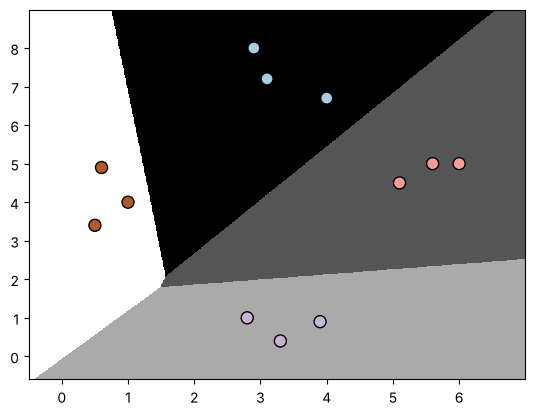

In [5]:
from sklearn import linear_model
from sklearn.multiclass import OneVsRestClassifier

# Вхідні дані: 12 точок, 4 класи
X = np.array([[3.1, 7.2], [4, 6.7], [2.9, 8], [5.1, 4.5],
              [6, 5], [5.6, 5], [3.3, 0.4],
              [3.9, 0.9], [2.8, 1],
              [0.5, 3.4], [1, 4], [0.6, 4.9]])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3])

# Логістичний класифікатор (один проти всіх)
classifier = OneVsRestClassifier(linear_model.LogisticRegression(solver='liblinear', C=1))
classifier.fit(X, y)

# Перевірка прогнозу на навчальних точках
print("True labels:     ", y)
print("Predicted labels:", classifier.predict(X))

visualize_classifier(classifier, X, y)

**Що отримано.** Передбачені мітки повністю збіглися зі справжніми – усі 12 точок класифіковано правильно. На графіку площина розбита на 4 зони різного відтінку, межі між зонами – прямі лінії. Це очікувано: логістична регресія лінійна, тому кожна межа між класами є прямою. Групи точок розташовані далеко одна від одної (зверху, справа, знизу та зліва), тому лінійних меж для їх розділення достатньо.

## Завдання 2.4. Наївний байєсовський класифікатор
*Завдання:* класифікувати дані з `data_multivar_nb.txt` гаусівським наївним байєсовським класифікатором, оцінити його якість трьома способами (на навчальних даних, на тестовій вибірці, перехресною перевіркою) і порівняти два прогони.

Файл містить 400 рядків: дві ознаки та номер класу (4 класи по 100 точок). Він зчитується через `np.loadtxt`, останній стовпець відокремлюється як `y`. Використано `GaussianNB` – він припускає, що в кожному класі ознаки мають нормальний розподіл і не залежать одна від одної. Перша оцінка – на тих самих даних, на яких модель навчалась.

Data shape: (400, 2)  classes: [0. 1. 2. 3.]
Accuracy of Naive Bayes classifier = 99.75 %
Errors: 1 of 400


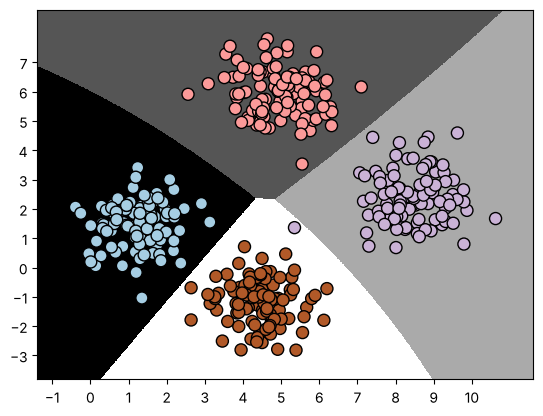

In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score

# Завантаження даних
input_file = 'data_multivar_nb.txt'
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]
print("Data shape:", X.shape, " classes:", np.unique(y))

# Навчання на всіх даних
classifier = GaussianNB()
classifier.fit(X, y)
y_pred = classifier.predict(X)

accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")
print("Errors:", (y != y_pred).sum(), "of", X.shape[0])

visualize_classifier(classifier, X, y)

**Що отримано.** На навчальних даних якість 99.75 % – помилка лише в 1 точці з 400. На графіку чотири кластери точок, а межі між зонами класів вигнуті, бо гаусівський класифікатор будує межі за формою розподілу кожного класу, а не прямими лініями.

Проте ця оцінка завищена: модель перевіряли на тих самих точках, які вона вже «бачила». Тому дані розділено на навчальну (80 %) і тестову (20 % = 80 точок) частини функцією `train_test_split` з `random_state=3`. Нова модель навчається лише на навчальній частині, а якість рахується на тестовій.

Accuracy of the new classifier = 100.0 %


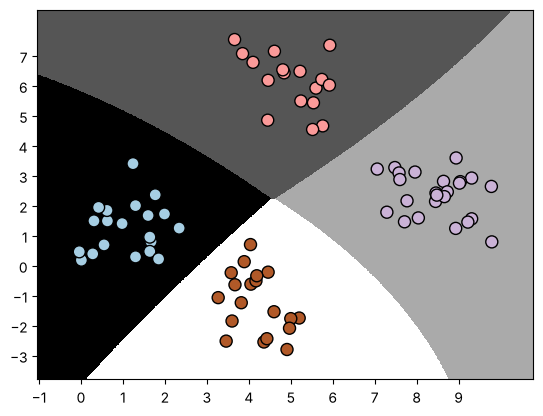

In [7]:
# Перший прогін: розбиття з random_state=3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)
classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)

accuracy = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy, 2), "%")

visualize_classifier(classifier_new, X_test, y_test)

**Що отримано.** На тестовій вибірці – 100 %, тобто всі 80 нових для моделі точок класифіковано правильно. На графіку показано лише тестові точки, жодна з них не потрапила в чужу зону.

Далі виконано потрійну перехресну перевірку `cross_val_score` з `cv=3`: дані ділять на 3 частини, і модель по черзі тестується на кожній, навчаючись на двох інших. Щоб не повторювати однаковий код чотири рази, метрики (accuracy, precision, recall, F1) пораховано в циклі. Для 4 класів взято зважені версії метрик (`_weighted`), які усереднюють результат по класах з урахуванням їх розміру.

In [8]:
# Перехресна перевірка
num_folds = 3
for metric in ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']:
    values = cross_val_score(classifier, X, y, scoring=metric, cv=num_folds)
    print(metric + ": " + str(round(100 * values.mean(), 2)) + "%")

accuracy: 99.75%
precision_weighted: 99.76%
recall_weighted: 99.75%
f1_weighted: 99.75%


**Що отримано.** Accuracy 99.75 %, precision 99.76 %, recall 99.75 %, F1 99.75 %. Значення майже не відрізняються одне від одного, бо класи однакового розміру і помилок практично немає.

Для другого прогону дані розбито з іншим `random_state=10`, тобто в тестову частину потрапляє інший набір точок.

Accuracy of the classifier (second run) = 98.75 %
Errors: 1 of 80


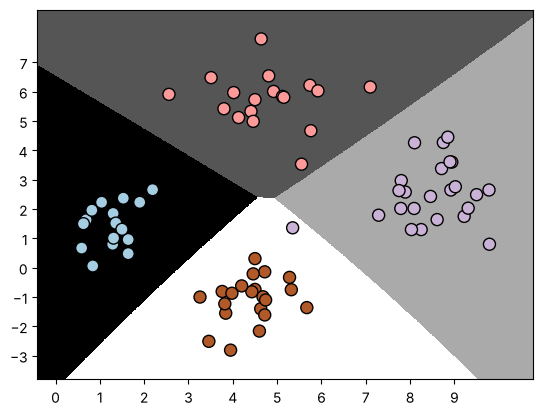

In [9]:
# Другий прогін: розбиття з random_state=10
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=10)
classifier_2 = GaussianNB()
classifier_2.fit(X_train2, y_train2)
y_test_pred2 = classifier_2.predict(X_test2)

accuracy = 100.0 * (y_test2 == y_test_pred2).sum() / X_test2.shape[0]
print("Accuracy of the classifier (second run) =", round(accuracy, 2), "%")
print("Errors:", (y_test2 != y_test_pred2).sum(), "of", X_test2.shape[0])

visualize_classifier(classifier_2, X_test2, y_test2)

**Порівняння двох прогонів.** Перший прогін дав 100 %, другий – 98.75 % (1 помилка з 80). Модель та сама, різниця лише в тому, які точки опинилися в тесті: у другому випадку туди потрапила точка, що лежить близько до межі двох класів. Отже, результат на одному випадковому розбитті може «пощастити» або «не пощастити», а перехресна перевірка (99.75 %) усереднює кілька розбиттів і дає надійнішу оцінку. В обох прогонах якість дуже висока, тож для цих даних наївний байєсовський класифікатор підходить добре.

## Завдання 2.5. Метрики якості класифікації
*Завдання:* для двох моделей бінарної класифікації (RF і LR) порахувати матрицю помилок, accuracy, recall, precision, F1 – вбудованими функціями sklearn і власними функціями, – дослідити вплив порогу, побудувати ROC-криві, обчислити AUC і визначити кращу модель.

У файлі `data_metrics.csv` для кожного об'єкта є справжня мітка `actual_label` і ймовірності класу 1 від двох моделей: `model_RF` і `model_LR`. Дані зчитано через pandas, а ймовірності перетворено на мітки з порогом 0.5.

In [10]:
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score
from sklearn.metrics import precision_score, f1_score, roc_curve, roc_auc_score

df = pd.read_csv('data_metrics.csv')
print("Rows:", len(df))
print(df.head())

thresh = 0.5
df['predicted_RF'] = (df.model_RF >= 0.5).astype('int')
df['predicted_LR'] = (df.model_LR >= 0.5).astype('int')
print(df.head())

Rows: 15758
   actual_label  model_RF  model_LR
0             1  0.639816  0.531904
1             0  0.490993  0.414496
2             1  0.623815  0.569883
3             1  0.506616  0.443674
4             0  0.418302  0.369532
   actual_label  model_RF  model_LR  predicted_RF  predicted_LR
0             1  0.639816  0.531904             1             1
1             0  0.490993  0.414496             0             0
2             1  0.623815  0.569883             1             1
3             1  0.506616  0.443674             1             0
4             0  0.418302  0.369532             0             0


**Що отримано.** У файлі 15 758 об'єктів. Після застосування порогу з'явились стовпці `predicted_RF` і `predicted_LR`. Уже в перших п'яти рядках видно, що моделі іноді не згодні: для рядка з індексом 3 RF дає ймовірність 0.507 (мітка 1), а LR – 0.444 (мітка 0).

### Матриця помилок
Власні функції `ovcharuk_find_TP`, `ovcharuk_find_FN`, `ovcharuk_find_FP`, `ovcharuk_find_TN` рахують кількість об'єктів у кожному з чотирьох сегментів: умова на справжню і передбачену мітку перевіряється поелементно, а `sum` рахує кількість збігів. Функція `ovcharuk_confusion_matrix` складає їх у матрицю [[TN, FP], [FN, TP]] – такий самий порядок, як у sklearn. Збіг з `confusion_matrix` перевірено `assert` для RF і для LR.

In [11]:
print(confusion_matrix(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_find_TP(y_true, y_pred):
    # counts the number of true positives (y_true = 1, y_pred = 1)
    return sum((y_true == 1) & (y_pred == 1))

def ovcharuk_find_FN(y_true, y_pred):
    # counts the number of false negatives (y_true = 1, y_pred = 0)
    return sum((y_true == 1) & (y_pred == 0))

def ovcharuk_find_FP(y_true, y_pred):
    # counts the number of false positives (y_true = 0, y_pred = 1)
    return sum((y_true == 0) & (y_pred == 1))

def ovcharuk_find_TN(y_true, y_pred):
    # counts the number of true negatives (y_true = 0, y_pred = 0)
    return sum((y_true == 0) & (y_pred == 0))

print('TP:', ovcharuk_find_TP(df.actual_label.values, df.predicted_RF.values))
print('FN:', ovcharuk_find_FN(df.actual_label.values, df.predicted_RF.values))
print('FP:', ovcharuk_find_FP(df.actual_label.values, df.predicted_RF.values))
print('TN:', ovcharuk_find_TN(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_find_conf_matrix_values(y_true, y_pred):
    # calculate TP, FN, FP, TN
    TP = ovcharuk_find_TP(y_true, y_pred)
    FN = ovcharuk_find_FN(y_true, y_pred)
    FP = ovcharuk_find_FP(y_true, y_pred)
    TN = ovcharuk_find_TN(y_true, y_pred)
    return TP, FN, FP, TN

def ovcharuk_confusion_matrix(y_true, y_pred):
    TP, FN, FP, TN = ovcharuk_find_conf_matrix_values(y_true, y_pred)
    return np.array([[TN, FP], [FN, TP]])

print(ovcharuk_confusion_matrix(df.actual_label.values, df.predicted_RF.values))

assert np.array_equal(ovcharuk_confusion_matrix(df.actual_label.values, df.predicted_RF.values),
                      confusion_matrix(df.actual_label.values, df.predicted_RF.values)), \
    'ovcharuk_confusion_matrix() is not correct for RF'
assert np.array_equal(ovcharuk_confusion_matrix(df.actual_label.values, df.predicted_LR.values),
                      confusion_matrix(df.actual_label.values, df.predicted_LR.values)), \
    'ovcharuk_confusion_matrix() is not correct for LR'
print('confusion matrix check: OK')

[[5519 2360]
 [2832 5047]]
TP: 5047
FN: 2832
FP: 2360
TN: 5519
[[5519 2360]
 [2832 5047]]
confusion matrix check: OK


**Що отримано.** Для RF: TP = 5047, FN = 2832, FP = 2360, TN = 5519. Власна матриця збігається з матрицею sklearn для обох моделей (перевірка виводить «OK»). Видно, що RF помиляється в обидва боки приблизно однаково часто: пропущено 2832 позитивних, хибно знайдено 2360.

### Accuracy, recall, precision, F1
Наступні функції рахують метрики через значення з матриці помилок:
- `ovcharuk_accuracy_score`: (TP + TN) / (TP + FN + FP + TN), тобто частка всіх правильних відповідей;
- `ovcharuk_recall_score`: TP / (TP + FN), тобто скільки справжніх одиниць модель знайшла;
- `ovcharuk_precision_score`: TP / (TP + FP), тобто скільки з передбачених одиниць справді є одиницями;
- `ovcharuk_f1_score`: 2 · P · R / (P + R), тобто середнє гармонійне точності й повноти.

Кожна функція перевірена через `assert` проти функції sklearn. Для F1 порівняння зроблено через `np.isclose`, бо через округлення дробових чисел результат може відрізнятися в останньому знаку.

In [12]:
print(accuracy_score(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_accuracy_score(y_true, y_pred):
    # calculates the fraction of samples
    TP, FN, FP, TN = ovcharuk_find_conf_matrix_values(y_true, y_pred)
    return (TP + TN) / (TP + FN + FP + TN)

assert ovcharuk_accuracy_score(df.actual_label.values, df.predicted_RF.values) == accuracy_score(
    df.actual_label.values, df.predicted_RF.values), 'ovcharuk_accuracy_score failed on RF'
assert ovcharuk_accuracy_score(df.actual_label.values, df.predicted_LR.values) == accuracy_score(
    df.actual_label.values, df.predicted_LR.values), 'ovcharuk_accuracy_score failed on LR'
print('Accuracy RF: %.3f' % (ovcharuk_accuracy_score(df.actual_label.values, df.predicted_RF.values)))
print('Accuracy LR: %.3f' % (ovcharuk_accuracy_score(df.actual_label.values, df.predicted_LR.values)))

print(recall_score(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_recall_score(y_true, y_pred):
    # calculates the fraction of positive samples predicted correctly
    TP, FN, FP, TN = ovcharuk_find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FN)

assert ovcharuk_recall_score(df.actual_label.values, df.predicted_RF.values) == recall_score(
    df.actual_label.values, df.predicted_RF.values), 'ovcharuk_recall_score failed on RF'
assert ovcharuk_recall_score(df.actual_label.values, df.predicted_LR.values) == recall_score(
    df.actual_label.values, df.predicted_LR.values), 'ovcharuk_recall_score failed on LR'
print('Recall RF: %.3f' % (ovcharuk_recall_score(df.actual_label.values, df.predicted_RF.values)))
print('Recall LR: %.3f' % (ovcharuk_recall_score(df.actual_label.values, df.predicted_LR.values)))

print(precision_score(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_precision_score(y_true, y_pred):
    # calculates the fraction of predicted positives samples that are actually positive
    TP, FN, FP, TN = ovcharuk_find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FP)

assert ovcharuk_precision_score(df.actual_label.values, df.predicted_RF.values) == precision_score(
    df.actual_label.values, df.predicted_RF.values), 'ovcharuk_precision_score failed on RF'
assert ovcharuk_precision_score(df.actual_label.values, df.predicted_LR.values) == precision_score(
    df.actual_label.values, df.predicted_LR.values), 'ovcharuk_precision_score failed on LR'
print('Precision RF: %.3f' % (ovcharuk_precision_score(df.actual_label.values, df.predicted_RF.values)))
print('Precision LR: %.3f' % (ovcharuk_precision_score(df.actual_label.values, df.predicted_LR.values)))

print(f1_score(df.actual_label.values, df.predicted_RF.values))

def ovcharuk_f1_score(y_true, y_pred):
    # calculates the F1 score
    recall = ovcharuk_recall_score(y_true, y_pred)
    precision = ovcharuk_precision_score(y_true, y_pred)
    return 2 * (precision * recall) / (precision + recall)

assert np.isclose(ovcharuk_f1_score(df.actual_label.values, df.predicted_RF.values),
                  f1_score(df.actual_label.values, df.predicted_RF.values)), 'ovcharuk_f1_score failed on RF'
assert np.isclose(ovcharuk_f1_score(df.actual_label.values, df.predicted_LR.values),
                  f1_score(df.actual_label.values, df.predicted_LR.values)), 'ovcharuk_f1_score failed on LR'
print('F1 RF: %.3f' % (ovcharuk_f1_score(df.actual_label.values, df.predicted_RF.values)))
print('F1 LR: %.3f' % (ovcharuk_f1_score(df.actual_label.values, df.predicted_LR.values)))

0.6705165630156111
Accuracy RF: 0.671
Accuracy LR: 0.616
0.6405635232897576
Recall RF: 0.641
Recall LR: 0.543
0.681382476036182
Precision RF: 0.681
Precision LR: 0.636
0.660342797330891
F1 RF: 0.660
F1 LR: 0.586


**Що отримано.** Усі `assert` пройшли, тобто власні функції рахують так само, як sklearn. Accuracy RF = 0.6705…, що збігається з відповіддю в методичці. Підсумок при порозі 0.5:

| | Accuracy | Recall | Precision | F1 |
|---|---|---|---|---|
| RF | 0.671 | 0.641 | 0.681 | 0.660 |
| LR | 0.616 | 0.543 | 0.636 | 0.586 |

RF випереджає LR за кожною метрикою. Найбільший розрив у recall (≈ 0.10): LR пропускає майже половину позитивних об'єктів.

### Як поріг впливає на метрики
Ті самі метрики RF пораховано для порогу 0.5 і для порогу 0.25.

In [13]:
y_true = df.actual_label.values
for t in [0.5, 0.25]:
    y_pred_t = (df.model_RF >= t).astype('int').values
    print('scores with threshold = %.2f' % t)
    print('Accuracy RF: %.3f' % ovcharuk_accuracy_score(y_true, y_pred_t))
    print('Recall RF: %.3f' % ovcharuk_recall_score(y_true, y_pred_t))
    print('Precision RF: %.3f' % ovcharuk_precision_score(y_true, y_pred_t))
    print('F1 RF: %.3f' % ovcharuk_f1_score(y_true, y_pred_t))
    print('')

scores with threshold = 0.50
Accuracy RF: 0.671
Recall RF: 0.641
Precision RF: 0.681
F1 RF: 0.660

scores with threshold = 0.25
Accuracy RF: 0.502
Recall RF: 1.000
Precision RF: 0.501
F1 RF: 0.668



**Порівняння порогів.** Коли поріг знижено до 0.25, recall піднявся з 0.641 до 1.000 – модель більше не пропускає жодного позитивного об'єкта. Ціна за це – precision упав з 0.681 до 0.501, а accuracy з 0.671 до 0.502: модель тепер позначає одиницею майже все підряд. F1 практично не змінилась (0.660 → 0.668), бо виграш у повноті з'їдається втратою точності. Висновок: зниження порогу збільшує повноту та зменшує точність, підвищення – навпаки. Поріг треба обирати залежно від того, що в конкретній задачі гірше – пропустити позитивний випадок чи дати хибну тривогу.

### ROC-крива та AUC
`roc_curve` приймає справжні мітки та ймовірності (не мітки!) і повертає FPR = FP / (FP + TN) та TPR = TP / (TP + FN) для кожного можливого порогу. За цими точками побудовано ROC-криві RF (червона) та LR (синя), разом з лінією випадкової моделі (чорна) та ідеальної (зелена). `roc_auc_score` рахує площу під кривою; на другому графіку значення AUC додано в легенду.

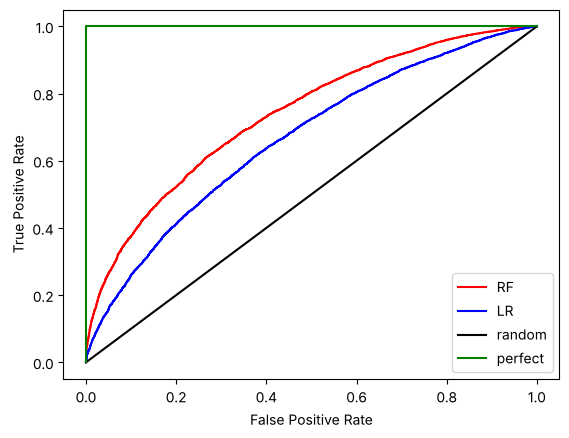

AUC RF:0.738
AUC LR:0.666


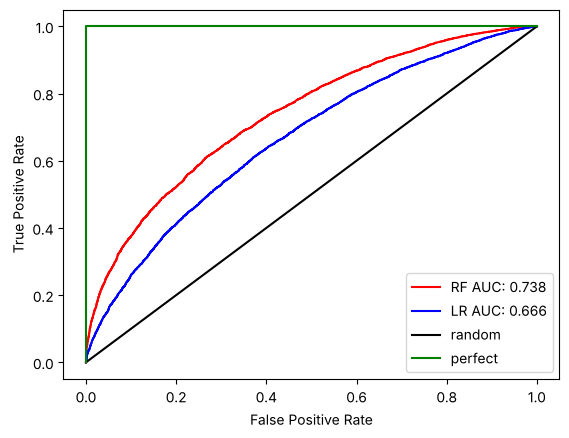

In [14]:
fpr_RF, tpr_RF, thresholds_RF = roc_curve(df.actual_label.values, df.model_RF.values)
fpr_LR, tpr_LR, thresholds_LR = roc_curve(df.actual_label.values, df.model_LR.values)

plt.plot(fpr_RF, tpr_RF, 'r-', label='RF')
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR')
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

auc_RF = roc_auc_score(df.actual_label.values, df.model_RF.values)
auc_LR = roc_auc_score(df.actual_label.values, df.model_LR.values)
print('AUC RF:%.3f' % auc_RF)
print('AUC LR:%.3f' % auc_LR)

plt.plot(fpr_RF, tpr_RF, 'r-', label='RF AUC: %.3f' % auc_RF)
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR AUC: %.3f' % auc_LR)
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

**Що отримано.** Обидві криві йдуть над чорною діагоналлю, тому обидві моделі кращі за випадкове вгадування. Червона крива RF по всій довжині розташована вище за синю криву LR, тобто при будь-якому рівні хибних спрацьовувань RF знаходить більше справжніх позитивних. AUC RF = 0.738, AUC LR = 0.666.

**Яка модель краща.** RF. Вона краща за LR і за метриками при порозі 0.5 (accuracy, recall, precision, F1), і за AUC. Саме AUC тут найбільш переконливий аргумент, бо він не прив'язаний до конкретного порогу і показує, наскільки добре модель у цілому відділяє клас 1 від класу 0.

## Завдання 2.6. Машина опорних векторів (SVM)
*Завдання:* класифікувати дані `data_multivar_nb.txt` за допомогою SVM, порахувати показники якості, порівняти з наївним байєсовським класифікатором і обрати кращу модель.

Дані завантажено і розбито так само, як у завданні 2.4 (`test_size=0.2`, `random_state=3`), щоб моделі порівнювалися в однакових умовах. Для SVM (`SVC`) перевірено два ядра: лінійне (`kernel='linear'`), яке будує прямі межі, і радіальне (`kernel='rbf'`), яке дозволяє вигнуті межі. Кожну модель навчено на навчальній частині та перевірено на тестовій, а потім для SVM з обома ядрами та для `GaussianNB` пораховано accuracy, precision, recall і F1 потрійною перехресною перевіркою. Результати зведено в таблицю pandas.

SVM (linear) - accuracy on test data = 100.0 %
SVM (rbf) - accuracy on test data = 100.0 %
Naive Bayes - accuracy on test data = 100.0 %



                    SVM (linear)  SVM (rbf)  Naive Bayes
accuracy                   99.75      99.75        99.75
precision_weighted         99.76      99.76        99.76
recall_weighted            99.75      99.75        99.75
f1_weighted                99.75      99.75        99.75


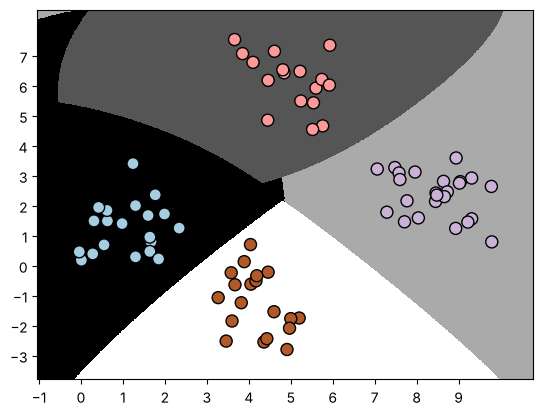

In [15]:
from sklearn.svm import SVC
import pandas as pd

# Завантаження та розбиття даних
data = np.loadtxt('data_multivar_nb.txt', delimiter=',')
X, y = data[:, :-1], data[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)

models = {
    'SVM (linear)': SVC(kernel='linear'),
    'SVM (rbf)': SVC(kernel='rbf'),
    'Naive Bayes': GaussianNB(),
}

# Якість на тестовій вибірці
for name, model in models.items():
    model.fit(X_train, y_train)
    acc = 100.0 * (model.predict(X_test) == y_test).mean()
    print(name, "- accuracy on test data =", round(acc, 2), "%")

# Перехресна перевірка (3 частини)
metrics = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
results = {}
for name, model in models.items():
    results[name] = [round(100 * cross_val_score(model, X, y, scoring=m, cv=3).mean(), 2) for m in metrics]
print()
print(pd.DataFrame(results, index=metrics))

# Межі класів SVM з ядром rbf на тестових даних
visualize_classifier(models['SVM (rbf)'], X_test, y_test)

**Що отримано.** На тестовій вибірці всі три моделі дали 100 %. За перехресною перевіркою результати теж однакові: accuracy 99.75 %, precision 99.76 %, recall 99.75 %, F1 99.75 % – і для SVM з лінійним ядром, і для SVM з rbf, і для наївного Байєса. На графіку межі SVM (rbf) плавно огинають групи точок, і всі тестові точки лежать у своїх зонах.

**Яку модель обрати.** На цих даних моделі рівні за якістю, бо чотири класи добре відокремлені і правильно розділяються навіть лінійними межами. Коли якість однакова, вирішують інші фактори. Наївний байєсовський класифікатор простіший: навчається практично миттєво і не має параметрів, які треба підбирати. SVM потребує вибору ядра та параметрів `C` і `gamma`, і на великих даних навчається повільніше. Тому для цієї задачі я б обрав наївний байєсовський класифікатор. SVM має сенс, коли класи перекриваються або межі між ними складної форми – там гнучкість ядер дає реальний виграш.

## Висновки
У роботі розглянуто основні методи попередньої обробки даних бібліотеки sklearn: бінаризацію, стандартизацію (виключення середнього), масштабування MinMax, L1- та L2-нормалізацію і кодування міток. Ці методи приводять дані до однакового масштабу та числового вигляду, з яким працюють алгоритми машинного навчання. Методи застосовано також до даних варіанту 11.

Далі досліджено контрольовану класифікацію. Логістична регресія (схема «один проти всіх») правильно розділила 4 класи прямими межами. Наївний байєсовський класифікатор на даних `data_multivar_nb.txt` показав 99.75 % за перехресною перевіркою; два прогони з різним розбиттям (100 % і 98.75 %) показали, що оцінка на одному тестовому наборі нестабільна, і перехресна перевірка надійніша.

Для порівняння моделей RF і LR написано власні функції матриці помилок, accuracy, recall, precision і F1, всі вони збіглися з функціями sklearn. RF краща за LR за всіма метриками та за AUC (0.738 проти 0.666). Зміна порогу показала компроміс між повнотою і точністю. SVM з лінійним і rbf ядром дав таку саму якість, як наївний Байєс (99.75 %), тому для цих даних доцільно обрати простішу модель – наївний байєсовський класифікатор.

Код програм завантажено на GitHub.